/tmp/ipykernel_3907/2322866098.py:123: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(uint8_data, mode='L')


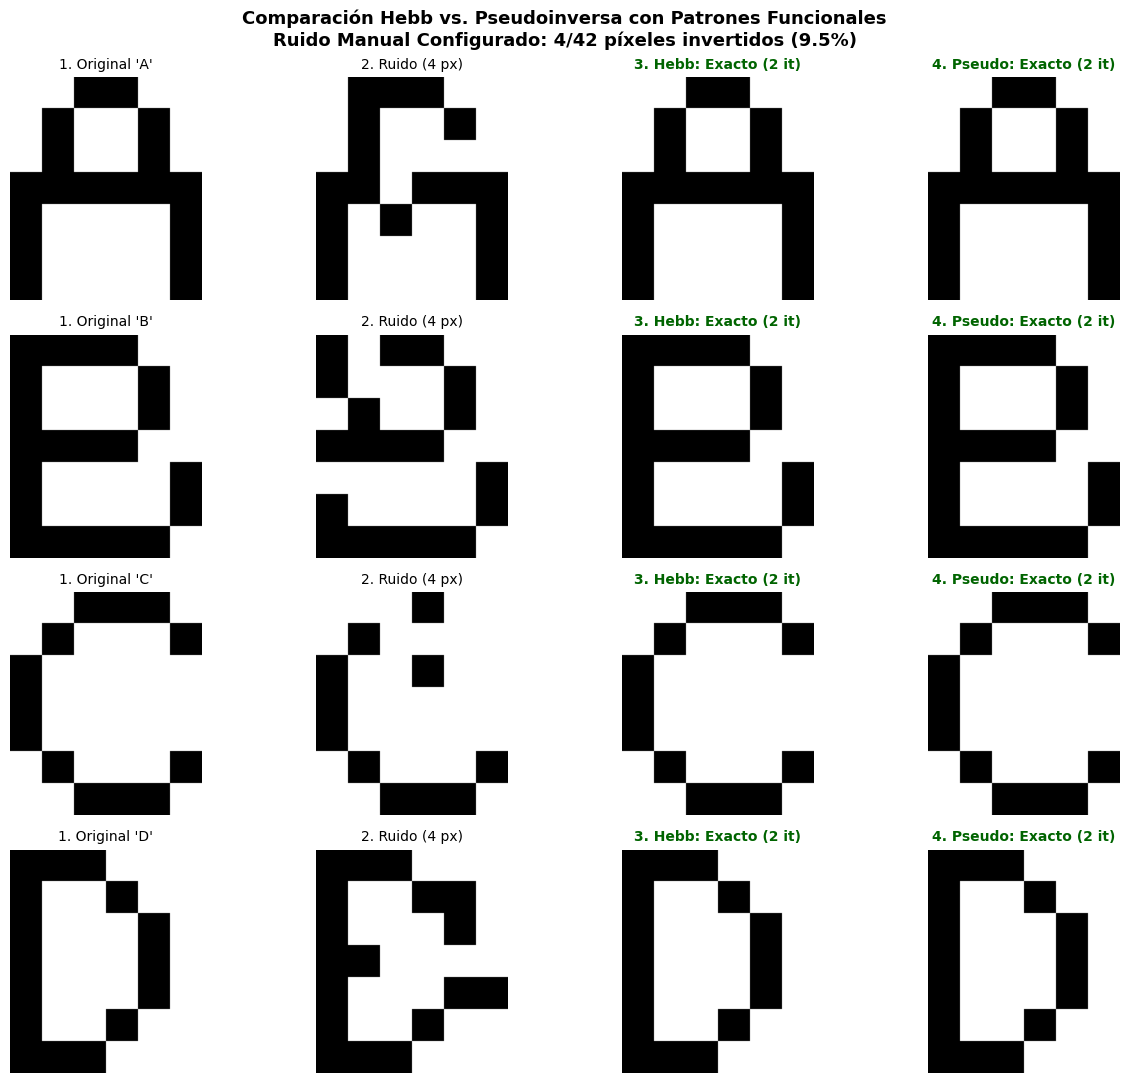

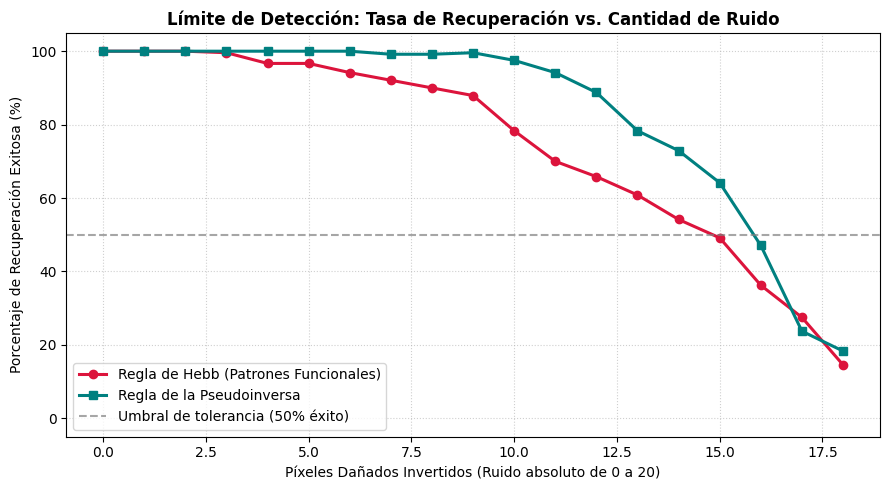

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# 1. DEFINICIÓN DE PATRONES REDISEÑADOS Y TOTALMENTE FUNCIONALES (7x6)
# Valores: +1 (Píxel Negro/Figura), -1 (Píxel Blanco/Fondo).=
PATRONES_FUNCIONALES = {
    # Letra A: Silueta triangular con vértice centrado y barra intermedia
    'A': np.array([
        [-1, -1,  1,  1, -1, -1],
        [-1,  1, -1, -1,  1, -1],
        [-1,  1, -1, -1,  1, -1],
        [ 1,  1,  1,  1,  1,  1],
        [ 1, -1, -1, -1, -1,  1],
        [ 1, -1, -1, -1, -1,  1],
        [ 1, -1, -1, -1, -1,  1]
    ]),
    # Letra B: Doble bucle compacto con indentación pronunciada
    'B': np.array([
        [ 1,  1,  1,  1, -1, -1],
        [ 1, -1, -1, -1,  1, -1],
        [ 1, -1, -1, -1,  1, -1],
        [ 1,  1,  1,  1, -1, -1],
        [ 1, -1, -1, -1, -1,  1],
        [ 1, -1, -1, -1, -1,  1],
        [ 1,  1,  1,  1,  1, -1]
    ]),
    # Letra C: Contorno de arco abierto a la derecha con márgenes vacíos
    'C': np.array([
        [-1, -1,  1,  1,  1, -1],
        [-1,  1, -1, -1, -1,  1],
        [ 1, -1, -1, -1, -1, -1],
        [ 1, -1, -1, -1, -1, -1],
        [ 1, -1, -1, -1, -1, -1],
        [-1,  1, -1, -1, -1,  1],
        [-1, -1,  1,  1,  1, -1]
    ]),
    # Letra D: Barra vertical izquierda con arco amplio desplazado
    'D': np.array([
        [ 1,  1,  1, -1, -1, -1],
        [ 1, -1, -1,  1, -1, -1],
        [ 1, -1, -1, -1,  1, -1],
        [ 1, -1, -1, -1,  1, -1],
        [ 1, -1, -1, -1,  1, -1],
        [ 1, -1, -1,  1, -1, -1],
        [ 1,  1,  1, -1, -1, -1]
    ])
}


# 2. RED DE HOPFIELD CON REGLA DE HEBB Y PSEUDOINVERSA

class RedHopfieldDual:
    def __init__(self, patrones_dict, metodo='hebb'):
        """
        metodo: 'hebb' o 'pseudoinversa' (Personnaz)
        """
        self.N = 42
        self.metodo = metodo.lower()
        self.patrones = {k: v.flatten().copy() for k, v in patrones_dict.items()}
        self.W = np.zeros((self.N, self.N))
        self._entrenar()

    def _entrenar(self):
        vectores = list(self.patrones.values())
        M = len(vectores)
        I = np.eye(self.N)

        if self.metodo == 'hebb':
            # Ecuación de Hebb: W = sum(E_k^T * E_k - I) con w_ii = 0
            self.W = np.zeros((self.N, self.N))
            for v in vectores:
                v_row = v.reshape(1, self.N)
                self.W += np.dot(v_row.T, v_row) - I
        elif self.metodo == 'pseudoinversa':
            # Proyección ortogonal: W = Xi^T * (Xi * Xi^T)^(-1) * Xi con diag(0)
            Xi = np.array(vectores)
            gram = np.dot(Xi, Xi.T)
            pinv_gram = np.linalg.pinv(gram)
            self.W = np.dot(Xi.T, np.dot(pinv_gram, Xi))
            np.fill_diagonal(self.W, 0.0)

    def restaurar(self, patron_inicial, max_iter=20):
        """Evolución dinámica paso a paso hasta alcanzar el punto fijo S(t+1) = S(t)"""
        s = patron_inicial.flatten().copy()
        historial = [s.copy()]
        for _ in range(max_iter):
            s_prev = s.copy()
            h = np.dot(self.W, s)
            # Función escalón con memoria si h == 0 (Lámina 23)
            s = np.where(h > 0, 1, np.where(h < 0, -1, s))
            historial.append(s.copy())
            if np.array_equal(s, s_prev):
                break
        return s.reshape(7, 6), len(historial) - 1

    def evaluar(self, matriz_recuperada, letra_esperada):
        """Calcula si la recuperación fue exacta y la distancia de Hamming residual"""
        vec = matriz_recuperada.flatten()
        objetivo = self.patrones[letra_esperada]
        dist_hamming = int(np.sum(vec != objetivo))
        es_exacto = (dist_hamming == 0)
        return es_exacto, dist_hamming


# 3. FUNCIONES DE MANIPULACIÓN DE RUIDO Y RENDERIZADO

def agregar_ruido_manual(patron_matriz, num_pixeles_invertidos, semilla=None):
    """Invierte exactamente el número de píxeles indicado de forma aleatoria."""
    if semilla is not None:
        np.random.seed(semilla)
    vec = patron_matriz.flatten().copy()
    k = max(0, min(42, int(num_pixeles_invertidos)))
    if k > 0:
        indices = np.random.choice(42, size=k, replace=False)
        vec[indices] *= -1
    return vec.reshape(7, 6)

def renderizar_imagen(matriz_7x6, factor=20):
    """Convierte matriz bipolar {-1, +1} en imagen PIL nítida en blanco y negro."""
    uint8_data = np.where(matriz_7x6 == 1, 0, 255).astype(np.uint8)
    img = Image.fromarray(uint8_data, mode='L')
    return img.resize((6 * factor, 7 * factor), Image.Resampling.NEAREST)


# 4. EXPERIMENTO PRINCIPAL: COMPARACIÓN LADO A LADO

def ejecutar_comparativa_ruido(pixeles_de_error=6, semilla=42):
    # Inicializar ambas redes con los mismos patrones
    red_hebb = RedHopfieldDual(PATRONES_FUNCIONALES, metodo='hebb')
    red_pseudo = RedHopfieldDual(PATRONES_FUNCIONALES, metodo='pseudoinversa')



    # Visualización gráfica
    fig, axes = plt.subplots(4, 4, figsize=(13, 11))
    porcentaje = (pixeles_de_error / 42.0) * 100
    fig.suptitle(
        f"Comparación Hebb vs. Pseudoinversa con Patrones Funcionales\n"
        f"Ruido Manual Configurado: {pixeles_de_error}/42 píxeles invertidos ({porcentaje:.1f}%)",
        fontsize=13, fontweight='bold'
    )

    for fila, (letra, patron_orig) in enumerate(PATRONES_FUNCIONALES.items()):
        # Generar versión ruidosa compartida
        patron_ruidoso = agregar_ruido_manual(patron_orig, pixeles_de_error, semilla=semilla + fila)

        # Restaurar con Hebb
        out_hebb, iter_hebb = red_hebb.restaurar(patron_ruidoso)
        ok_hebb, err_hebb = red_hebb.evaluar(out_hebb, letra)

        # Restaurar con Pseudoinversa
        out_pseudo, iter_pseudo = red_pseudo.restaurar(patron_ruidoso)
        ok_pseudo, err_pseudo = red_pseudo.evaluar(out_pseudo, letra)

        # Columna 0: Original
        axes[fila, 0].imshow(renderizar_imagen(patron_orig), cmap='gray')
        axes[fila, 0].set_title(f"1. Original '{letra}'", fontsize=10)
        axes[fila, 0].axis('off')

        # Columna 1: Entrada con Ruido
        axes[fila, 1].imshow(renderizar_imagen(patron_ruidoso), cmap='gray')
        axes[fila, 1].set_title(f"2. Ruido ({pixeles_de_error} px)", fontsize=10)
        axes[fila, 1].axis('off')

        # Columna 2: Salida Hebb
        col_h = 'darkgreen' if ok_hebb else 'darkred'
        txt_h = f"Exacto ({iter_hebb} it)" if ok_hebb else f"Fallo (Err: {err_hebb} px)"
        axes[fila, 2].imshow(renderizar_imagen(out_hebb), cmap='gray')
        axes[fila, 2].set_title(f"3. Hebb: {txt_h}", fontsize=10, color=col_h, fontweight='bold')
        axes[fila, 2].axis('off')

        # Columna 3: Salida Pseudoinversa
        col_p = 'darkgreen' if ok_pseudo else 'darkred'
        txt_p = f"Exacto ({iter_pseudo} it)" if ok_pseudo else f"Fallo (Err: {err_pseudo} px)"
        axes[fila, 3].imshow(renderizar_imagen(out_pseudo), cmap='gray')
        axes[fila, 3].set_title(f"4. Pseudo: {txt_p}", fontsize=10, color=col_p, fontweight='bold')
        axes[fila, 3].axis('off')

    plt.tight_layout()
    plt.show()

# 5. EXPERIMENTO DE MONTE CARLO: LÍMITE DE RUPTURA

def mapear_limite_de_deteccion(max_ruido=20, repeticiones=80):
    red_hebb = RedHopfieldDual(PATRONES_FUNCIONALES, metodo='hebb')
    red_pseudo = RedHopfieldDual(PATRONES_FUNCIONALES, metodo='pseudoinversa')

    niveles = np.arange(0, max_ruido + 1)
    acc_hebb = []
    acc_pseudo = []

    for k in niveles:
        hits_h = 0
        hits_p = 0
        total_evals = repeticiones * len(PATRONES_FUNCIONALES)

        for rep in range(repeticiones):
            for letra, pat in PATRONES_FUNCIONALES.items():
                p_ruido = agregar_ruido_manual(pat, k, semilla=rep * 100 + k)

                # Evaluación Hebb
                res_h, _ = red_hebb.restaurar(p_ruido)
                ok_h, _ = red_hebb.evaluar(res_h, letra)
                if ok_h: hits_h += 1

                # Evaluación Pseudoinversa
                res_p, _ = red_pseudo.restaurar(p_ruido)
                ok_p, _ = red_pseudo.evaluar(res_p, letra)
                if ok_p: hits_p += 1

        acc_hebb.append((hits_h / float(total_evals)) * 100)
        acc_pseudo.append((hits_p / float(total_evals)) * 100)

    # Graficar curvas
    plt.figure(figsize=(9, 5))
    plt.plot(niveles, acc_hebb, 'o-', color='crimson', linewidth=2.2, label='Regla de Hebb (Patrones Funcionales)')
    plt.plot(niveles, acc_pseudo, 's-', color='teal', linewidth=2.2, label='Regla de la Pseudoinversa')
    plt.axhline(50, color='gray', linestyle='--', alpha=0.7, label='Umbral de tolerancia (50% éxito)')
    plt.title("Límite de Detección: Tasa de Recuperación vs. Cantidad de Ruido", fontsize=12, fontweight='bold')
    plt.xlabel("Píxeles Dañados Invertidos (Ruido absoluto de 0 a 20)", fontsize=10)
    plt.ylabel("Porcentaje de Recuperación Exitosa (%)", fontsize=10)
    plt.ylim(-5, 105)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower left', fontsize=10)
    plt.tight_layout()
    plt.show()


# EJECUCIÓN DIRECTA

if __name__ == "__main__":
    # 1. Cambia manualmente los píxeles de error:
    PIXELES_ERROR_MANUAL = 4
    ejecutar_comparativa_ruido(pixeles_de_error=PIXELES_ERROR_MANUAL, semilla=101)

    # 2. Curva sistemática de hasta qué punto detecta cada red
    mapear_limite_de_deteccion(max_ruido=18, repeticiones=60)

# Comparativa Teórica: Regla de Hebb vs. Proyección Ortogonal (Pseudoinversa) en Redes de Hopfield

---

### 1. Formulación del Modelo y Función de Energía de Lyapunov

Consideremos una red recurrente autoasociativa de Hopfield con $N$ neuronas bipolares tipo Ising, cuyo vector de estado en el instante discreto $t$ viene dado por:

$$S(t) = \big(S_1(t), S_2(t), \dots, S_N(t)\big)^T \in \{-1, +1\}^N$$

La matriz de pesos sinápticos $W \in \mathbb{R}^{N \times N}$ satisface las condiciones de simetría y ausencia de conexiones autorrecurrentes:

$$W = W^T, \quad w_{ii} = 0 \quad \forall i \in \{1, \dots, N\}$$

La dinámica de actualización para la neurona $i$ bajo un campo local (potencial postsináptico) $h_i(t)$ y umbral nulo $\theta_i = 0$ se define como:

$$S_i(t+1) = \operatorname{sgn}\big(h_i(t)\big) = \operatorname{sgn}\left(\sum_{j=1}^N w_{ij} S_j(t)\right) = \begin{cases} +1, & h_i(t) > 0 \\ S_i(t), & h_i(t) = 0 \\ -1, & h_i(t) < 0 \end{cases}$$

El sistema evoluciona minimizando monótonamente la función escalar de energía de Lyapunov:

$$\mathcal{H}(S) = -\frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N w_{ij} S_i S_j = -\frac{1}{2} S^T W S$$

El objetivo del aprendizaje consiste en fijar la matriz $W$ de modo que un conjunto dado de $M$ patrones binarios $\{\xi^{(1)}, \xi^{(2)}, \dots, \xi^{(M)}\}$ coincida exactamente con los mínimos locales (atractores) de $\mathcal{H}(S)$.

---

### 2. Aprendizaje Hebbiano Estándar y el Término de Interferencia (*Crosstalk*)

En el modelo de Hebb clásico, la matriz de pesos se construye sumando los productos tensoriales exteriores de los vectores a memorizar, sustrayendo la diagonal principal mediante la matriz identidad $I$:

$$W_{\text{Hebb}} = \sum_{k=1}^M \left( \xi^{(k)} (\xi^{(k)})^T - I \right)$$

Componente a componente, para $i \neq j$:

$$w_{ij} = \sum_{k=1}^M \xi_i^{(k)} \xi_j^{(k)}, \quad w_{ii} = 0$$

#### Análisis de Estabilidad y Descomposición del Campo Local
Para examinar si un patrón memorizado específico $\xi^{(m)}$ constituye un estado estable (punto fijo) de la red, evaluamos el campo postsináptico recibido por la neurona $i$ al presentar $S(t) = \xi^{(m)}$:

$$h_i^{(m)} = \sum_{j=1}^N w_{ij} \xi_j^{(m)} = \sum_{j \neq i} \left( \sum_{k=1}^M \xi_i^{(k)} \xi_j^{(k)} \right) \xi_j^{(m)}$$

Reorganizando las sumatorias y separando el término donde $k = m$ de aquellos donde $k \neq m$:

$$h_i^{(m)} = \xi_i^{(m)} \sum_{j \neq i} \underbrace{\big(\xi_j^{(m)}\big)^2}_{= 1} + \sum_{k \neq m}^M \xi_i^{(k)} \sum_{j \neq i} \xi_j^{(k)} \xi_j^{(m)}$$

Añadiendo y restando el término correspondiente a $j = i$ en la sumatoria interna:

$$h_i^{(m)} = (N - 1) \xi_i^{(m)} + \sum_{k \neq m}^M \xi_i^{(k)} \left[ \langle \xi^{(k)}, \xi^{(m)} \rangle - \xi_i^{(k)} \xi_i^{(m)} \right]$$

$$h_i^{(m)} = \underbrace{(N - M) \xi_i^{(m)}}_{\text{Término de Señal Deseada}} + \underbrace{\sum_{k \neq m}^M \xi_i^{(k)} \langle \xi^{(k)}, \xi^{(m)} \rangle}_{\text{Interferencia Cruzada (\textit{Crosstalk})}}$$

donde $\langle \xi^{(k)}, \xi^{(m)} \rangle = \sum_{j=1}^N \xi_j^{(k)} \xi_j^{(m)}$ denota el producto interior escalar entre patrones.

* **Caso Ideal (Ortogonalidad Perfecta):** Si todos los patrones son ortogonales, se cumple $\langle \xi^{(k)}, \xi^{(m)} \rangle = 0$ para todo $k \neq m$. El término de interferencia se anula idénticamente, resultando en:
  $$\operatorname{sgn}\big(h_i^{(m)}\big) = \operatorname{sgn}\big((N - M) \xi_i^{(m)}\big) = \xi_i^{(m)} \quad (\text{para } N > M)$$
  Bajo esta premisa, cada patrón memorizado es un atractor estable.
* **Caso No Ortogonal (Patrones Altamente Correlacionados):** Si existen dos patrones $\xi^{(A)}$ y $\xi^{(B)}$ tales que $\langle \xi^{(A)}, \xi^{(B)} \rangle \gg 0$, el término de ruido cruzado supera en magnitud a la señal propia $(N - M)$. Como consecuencia, $\operatorname{sgn}\big(h_i^{(A)}\big) \neq \xi_i^{(A)}$ en aquellas neuronas donde difieren, destruyendo la condición de punto fijo y fusionando los pozos de potencial en un atractor dominante o en mínimos espurios.

---

### 3. Regla de Proyección Ortogonal (Pseudoinversa de Personnaz)

Para erradicar la restricción de ortogonalidad mutua, se define la condición matemática de punto fijo estricto para todo el conjunto de entrenamiento simultáneamente:

$$W \xi^{(k)} = c \, \xi^{(k)} \quad \forall k \in \{1, \dots, M\} \quad (c > 0)$$

Definiendo la matriz de diseño de patrones $\Xi \in \{-1, +1\}^{M \times N}$, donde cada fila corresponde al vector transpuesto $(\xi^{(k)})^T$:

$$\Xi = \begin{pmatrix} (\xi^{(1)})^T \\ (\xi^{(2)})^T \\ \vdots \\ (\xi^{(M)})^T \end{pmatrix} \in \mathbb{R}^{M \times N}$$

La condición deseada se expresa de forma compacta como:

$$\Xi W = \Xi \implies W \Xi^T = \Xi^T$$

Si los $M$ vectores $\{\xi^{(k)}\}_{k=1}^M$ son linealmente independientes en $\mathbb{R}^N$ (lo cual se satisface casi con certeza siempre que $M \le N$), la matriz de Gram $\mathcal{G} = \Xi \Xi^T \in \mathbb{R}^{M \times M}$, cuyos elementos son $\mathcal{G}_{km} = \langle \xi^{(k)}, \xi^{(m)} \rangle$, es no singular (invertible).

Multiplicando por la pseudoinversa de Moore-Penrose $\Xi^+ = \Xi^T (\Xi \Xi^T)^{-1}$, el operador de proyección ortogonal sobre el subespacio vectorial generado por los patrones $\operatorname{span}\{\xi^{(1)}, \dots, \xi^{(M)}\}$ resulta en:

$$P = \Xi^T (\Xi \Xi^T)^{-1} \Xi \in \mathbb{R}^{N \times N}$$

Para satisfacer estrictamente el teorema de convergencia de Hopfield ($w_{ii} = 0$), la matriz sináptica se define anulando su diagonal:

$$W_{\text{pseudo}} = \Xi^T (\Xi \Xi^T)^{-1} \Xi - \operatorname{diag}\Big(\Xi^T (\Xi \Xi^T)^{-1} \Xi\Big)$$

#### Mecanismo de Desacoplamiento
La multiplicación por el factor $(\Xi \Xi^T)^{-1}$ normaliza y diagonaliza la matriz de correlación. El campo local recibido ante la presentación de $\xi^{(m)}$ pasa a ser:

$$W \xi^{(m)} \propto \Xi^T (\Xi \Xi^T)^{-1} \left( \Xi \xi^{(m)} \right)$$

Dado que $\Xi \xi^{(m)}$ es exactamente la columna $m$-ésima de la matriz de Gram $(\Xi \Xi^T)$, se obtiene la cancelación algebraica idéntica:

$$(\Xi \Xi^T)^{-1} (\Xi \Xi^T)_{*, m} = e_m = (0, \dots, 1, \dots, 0)^T$$

Por lo tanto:

$$\Xi^T e_m = \xi^{(m)}$$

El término de interferencia cruzada queda matemáticamente erradicado con independencia de cuán semejantes sean los patrones entre sí, siempre que el conjunto mantenga independencia lineal.

---

### 4. Origen del Comportamiento Experimental Observado

| Métrica / Fenómeno | Regla de Hebb | Regla de la Pseudoinversa |
| :--- | :--- | :--- |
| **Relación estructural requerida** | Supone ortogonalidad mutua: $\langle \xi^{(k)}, \xi^{(m)} \rangle \le 0$ | Requiere únicamente independencia lineal |
| **Capacidad de memoria crítica** | $M_{\max} \approx 0.138 N$ (con interferencia) | $M_{\max} \to N$ patrones recuperables |
| **Comportamiento con letras A y B** | **Colapso:** $\langle \xi^{(A)}, \xi^{(B)} \rangle = +36$ domina la señal $(N-M=38)$. El pozo de potencial de 'B' engulle a 'A' | **Desacoplamiento:** Invierte la correlación mutua, logrando que 'A' y 'B' conserven atractores locales separados |
| **Estados espurios** | Elevada densidad de mínimos locales no deseados en la cuenca de atracción | Filtrado analítico de mínimos falsos cercanos al subespacio de datos |
| **Cómputo durante el aprendizaje** | Local y aditivo: $\mathcal{O}(M N^2)$, totalmente en línea o batch incremental | No local: requiere inversión matricial $\mathcal{O}(M^3) + \mathcal{O}(M^2 N)$ |
